# Unemployment Analysis in India (CodeAlpha Internship - Task 2)

Analysis of unemployment rate data in India (May 2019 - June 2020), with a focus on the impact of Covid-19.

**Dataset:** `Unemployment in India.csv` (provided by CodeAlpha)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Unemployment in India.csv')

# Clean column names and give shorter names
df.columns = df.columns.str.strip()
df = df.rename(columns={
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'LPR'
})

# Remove completely empty rows
df = df.dropna(how='all')

# Remove extra spaces in text columns
for c in ['Region', 'Frequency', 'Area']:
    df[c] = df[c].str.strip()

# Convert Date from text to real date (day-month-year)
df['Date'] = pd.to_datetime(df['Date'].str.strip(), dayfirst=True)

print(df.shape)
print(df['Date'].min(), df['Date'].max())
print(df.isnull().sum().sum(), df.duplicated().sum())

(740, 7)
2019-05-31 00:00:00 2020-06-30 00:00:00
0 0

In [2]:
print(df.info())
print(df[['Unemployment_Rate', 'Employed', 'LPR']].describe().round(2))
print(df['Area'].value_counts())
print(df['Region'].nunique())
print(df.groupby('Area')['Unemployment_Rate'].mean().round(2))

<class 'pandas.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Region             740 non-null    str           
 1   Date               740 non-null    datetime64[us]
 2   Frequency          740 non-null    str           
 3   Unemployment_Rate  740 non-null    float64       
 4   Employed           740 non-null    float64       
 5   LPR                740 non-null    float64       
 6   Area               740 non-null    str           
dtypes: datetime64[us](1), float64(3), str(3)
memory usage: 46.2 KB
None
       Unemployment_Rate     Employed     LPR
count             740.00       740.00  740.00
mean               11.79   7204460.03   42.63
std                10.72   8087988.43    8.11
min                 0.00     49420.00   13.33
25%                 4.66   1190404.50   38.06
50%                 8.35   4744178.50   41.16
75%                15.

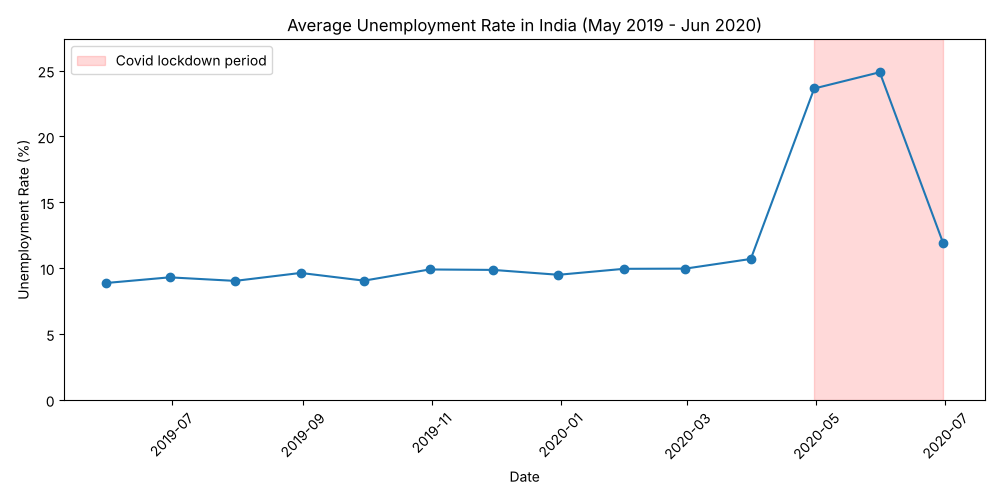

In [3]:
# Average unemployment rate for each month
monthly = df.groupby('Date')['Unemployment_Rate'].mean()

ymax = monthly.max() * 1.1
lockdown = monthly.index >= pd.Timestamp('2020-04-01')

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values, marker='o')
plt.fill_between(monthly.index, 0, ymax, where=lockdown,
                 color='red', alpha=0.15, label='Covid lockdown period')
plt.ylim(0, ymax)
plt.title('Average Unemployment Rate in India (May 2019 - Jun 2020)')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

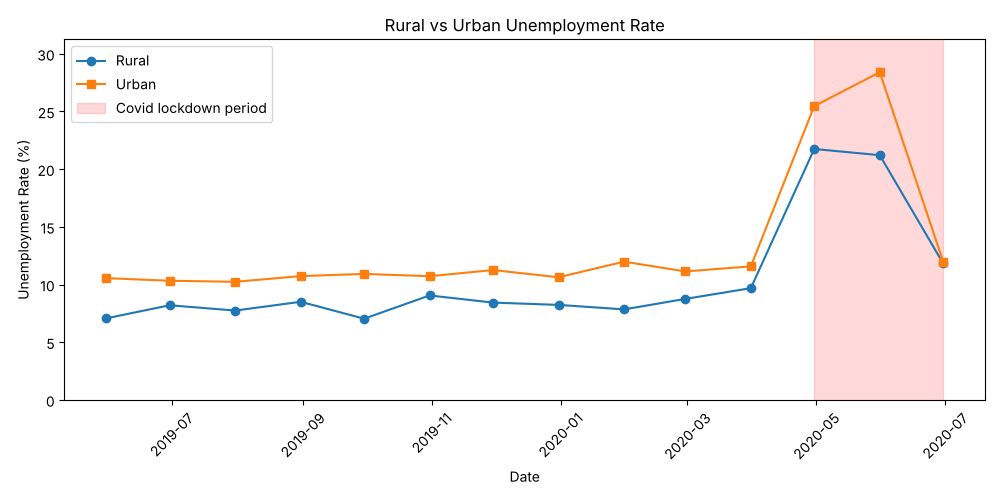

In [4]:
# Rural vs Urban monthly average
area_monthly = df.groupby(['Date', 'Area'])['Unemployment_Rate'].mean().unstack()

ymax = area_monthly.max().max() * 1.1
lockdown = area_monthly.index >= pd.Timestamp('2020-04-01')

plt.figure(figsize=(10, 5))
plt.plot(area_monthly.index, area_monthly['Rural'], marker='o', label='Rural')
plt.plot(area_monthly.index, area_monthly['Urban'], marker='s', label='Urban')
plt.fill_between(area_monthly.index, 0, ymax, where=lockdown,
                 color='red', alpha=0.15, label='Covid lockdown period')
plt.ylim(0, ymax)
plt.title('Rural vs Urban Unemployment Rate')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

                Pre_Covid  Lockdown  Increase
Region                                       
Puducherry            1.6      75.4      73.8
Jharkhand            14.3      57.1      42.8
Tamil Nadu            2.8      40.9      38.0
Bihar                13.8      47.2      33.4
Karnataka             3.2      24.5      21.2
Haryana              22.9      40.3      17.4
Madhya Pradesh        4.7      21.8      17.1
Andhra Pradesh        5.0      22.0      17.0
Telangana             4.7      21.4      16.7
Kerala                7.0      21.4      14.5

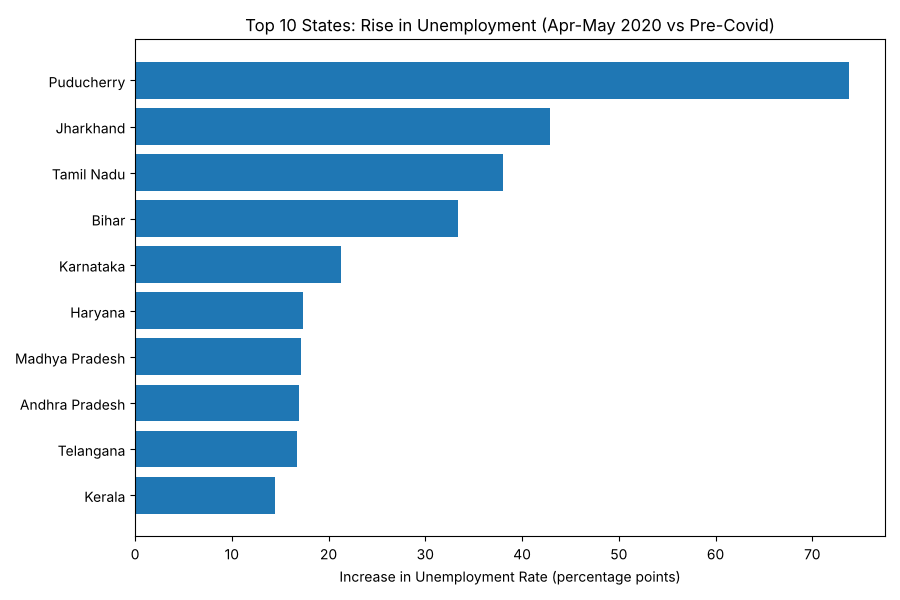

In [5]:
# Average before Covid (before March 2020), for each state
pre = df[df['Date'] < '2020-03-01'].groupby('Region')['Unemployment_Rate'].mean()

# Average during the lockdown months (April and May 2020)
lockdown_dates = pd.to_datetime(['2020-04-30', '2020-05-31'])
peak = df[df['Date'].isin(lockdown_dates)].groupby('Region')['Unemployment_Rate'].mean()

# Combine and calculate the increase
state = pd.DataFrame({'Pre_Covid': pre, 'Lockdown': peak}).dropna()
state['Increase'] = state['Lockdown'] - state['Pre_Covid']
state = state.sort_values('Increase', ascending=False)

print(state.round(1).head(10))

# Bar graph of the top 10 states
top10 = state.head(10).sort_values('Increase')
plt.figure(figsize=(9, 6))
plt.barh(top10.index, top10['Increase'])
plt.title('Top 10 States: Rise in Unemployment (Apr-May 2020 vs Pre-Covid)')
plt.xlabel('Increase in Unemployment Rate (percentage points)')
plt.tight_layout()
plt.show()

Date
May 2019    8.87
Jun 2019    9.30
Jul 2019    9.03
Aug 2019    9.64
Sep 2019    9.05
Oct 2019    9.90
Nov 2019    9.87
Dec 2019    9.50
Jan 2020    9.95
Feb 2020    9.96
Name: Unemployment_Rate, dtype: float64

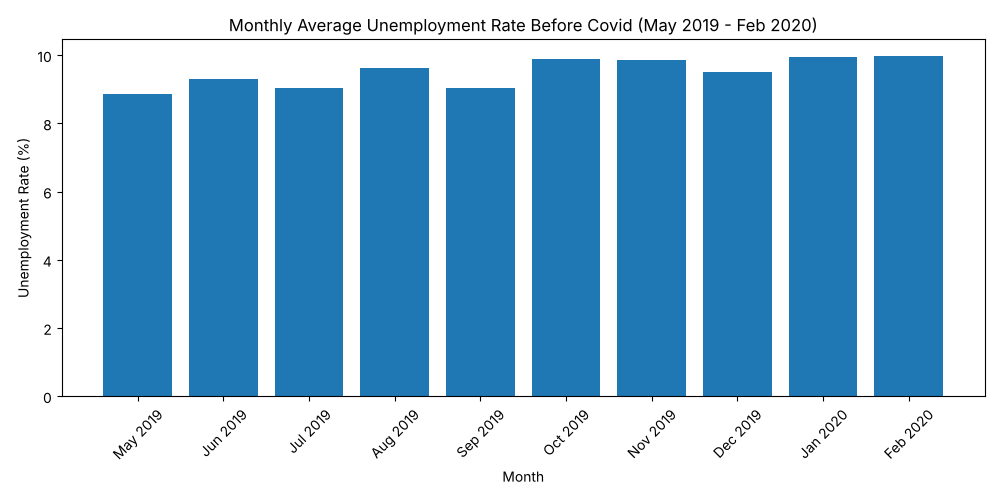

In [6]:
# Only the months before Covid
normal = df[df['Date'] < '2020-03-01']

# Average for each month
seasonal = normal.groupby(normal['Date'].dt.strftime('%b %Y'), sort=False)['Unemployment_Rate'].mean()
print(seasonal.round(2))

plt.figure(figsize=(10, 5))
plt.bar(seasonal.index, seasonal.values)
plt.title('Monthly Average Unemployment Rate Before Covid (May 2019 - Feb 2020)')
plt.xlabel('Month')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Conclusion and Insights

- Before Covid-19, unemployment stayed in a narrow band of about 9-10% (average across states).
- During the April-May 2020 lockdown it jumped to about 24-25%, and recovered to about 12% in June 2020.
- Urban areas were hit harder than rural areas (about 28% vs 21% in May 2020), but both recovered sharply by June.
- In this dataset, Puducherry, Jharkhand, Tamil Nadu and Bihar saw the sharpest rise during the lockdown. Puducherry is an extreme case.
- Before Covid, unemployment showed no clear seasonal pattern. A longer time series is needed to confirm seasonality.

## Policy Insights

- Urban workers in informal jobs need quick support (cash transfers, job schemes) during sudden lockdowns.
- States with a sharp rise should get targeted employment support first.
- Fast recovery after reopening shows that phased reopening helps jobs return.

*Note: figures are simple averages across states and may differ from official national rates.*